# 📊 Biais et approfondissement

> ✍️ **Notebook dirigé** · complétez les cellules marquées ✍️ À VOUS.

**Jour 1 · 14h15** · Exercice

*Analyse exploratoire et interprétation métier*

**Objectifs**
- Détecter les sur- et sous-représentations par rapport à une référence
- Quantifier les disparités d'une décision algorithmique avec Fairlearn
- Identifier les corrélations induites et les limites de l'analyse

In [ ]:
%pip install -q fairlearn
# ⚙️ À exécuter en premier : récupère la configuration du cours (quelques secondes)
import os, sys
CONFIG_ID = "1bW5RsToUHc-7pGiyHS_1B2OYkAFsrv3r"

# Suppression du fichier corrompu s'il existe
if os.path.exists("config_projet.py"):
    os.remove("config_projet.py")

# Téléchargement propre avec gdown pour contourner l'avertissement de virus Google Drive
!gdown --id {CONFIG_ID} -O config_projet.py

print("✅ Configuration prête : chaque fichier de données se télécharge au premier usage")


/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1bW5RsToUHc-7pGiyHS_1B2OYkAFsrv3r
From (redirected): https://drive.google.com/uc?id=1bW5RsToUHc-7pGiyHS_1B2OYkAFsrv3r&confirm=t&uuid=8afb54a8-1bc7-455e-8104-bd7c88fdb2db
To: /content/config_projet.py
100% 6.94k/6.94k [00:00<00:00, 14.8MB/s]
✅ Configuration prête : chaque fichier de données se télécharge au premier usage


In [ ]:
# Choisissez votre secteur : "commerce", "banque" ou "hotellerie"
SECTEUR = "commerce"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from config_projet import charger, reference, nettoyage_minimal

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
brut, cfg = charger(SECTEUR)
print(cfg["nom"], "·", brut.shape[0], "lignes,", brut.shape[1], "colonnes")

Maison Lumen · 24224 lignes, 16 colonnes


In [ ]:
from fairlearn.metrics import (MetricFrame, selection_rate, count, true_positive_rate,
                               demographic_parity_difference, demographic_parity_ratio)
df = nettoyage_minimal(brut, cfg)
for col in cfg["sensibles"]:
    df[col] = df[col].fillna("inconnu")
y = df[cfg["decision"]]
print("Décision étudiée :", cfg["decision_label"], f"· taux global {y.mean():.1%}")

Décision étudiée : offre personnalisée envoyée · taux global 40.6%


## 1. La représentativité
Sur les **clients uniques**, comparez la part de chaque modalité à la population de référence (`reference()`). Signalez les ratios inférieurs à 0,8 ou supérieurs à 1,25.

In [ ]:
# ✍️ À VOUS : remplacez les ... et traitez les TODO
# Clients uniques : un client compte une seule fois, quel que soit son nombre de commandes
clients_uniques = df.drop_duplicates(subset="client_id")
ref_df = reference()
print(f"{len(clients_uniques)} clients uniques")

lignes = []
for col in cfg["sensibles"]:
    # Parts calculées sur les valeurs renseignées ("inconnu" n'existe pas dans la référence)
    connus = clients_uniques.loc[clients_uniques[col] != "inconnu", col]
    dist_ech = connus.value_counts(normalize=True)
    for _, row in ref_df[ref_df["variable"] == col].iterrows():
        p_ech = dist_ech.get(row["modalite"], 0.0)
        ratio = p_ech / row["part_reference"] if row["part_reference"] > 0 else np.nan
        statut = "SOUS-représenté" if ratio < 0.8 else "SUR-représenté" if ratio > 1.25 else "OK"
        lignes.append({"variable": col, "modalite": row["modalite"],
                       "part_echantillon": p_ech, "part_reference": row["part_reference"],
                       "ratio": ratio, "statut": statut})

represent = pd.DataFrame(lignes)
display(represent.style.format({"part_echantillon": "{:.1%}", "part_reference": "{:.1%}", "ratio": "{:.2f}"})
        .map(lambda s: "color: red" if s != "OK" else "", subset=["statut"]))


6768 clients uniques


,variable,modalite,part_echantillon,part_reference,ratio,statut
0,tranche_age,18-24,13.9%,10.0%,1.39,SUR-représenté
1,tranche_age,25-34,29.5%,15.0%,1.97,SUR-représenté
2,tranche_age,35-44,25.3%,16.0%,1.58,SUR-représenté
3,tranche_age,45-54,16.4%,17.0%,0.96,OK
4,tranche_age,55-64,8.7%,16.0%,0.54,SOUS-représenté
5,tranche_age,65+,6.2%,26.0%,0.24,SOUS-représenté
6,genre,F,62.4%,52.0%,1.20,OK
7,genre,H,37.6%,48.0%,0.78,SOUS-représenté
8,region,Île-de-France,31.3%,19.0%,1.65,SUR-représenté
9,region,Nord-Est,17.0%,24.0%,0.71,SOUS-représenté


## 2. La parité de la décision
Pour chaque variable sensible, calculez avec `MetricFrame` le taux de décision favorable et l'effectif par groupe, puis l'écart et le ratio de parité démographique.

In [ ]:
# ✍️ À VOUS : remplacez les ... et traitez les TODO
synthese = []
for col in cfg["sensibles"]:
    # Pour la parité démographique, seule la décision compte : y_true n'est pas utilisé
    mf = MetricFrame(metrics={"taux_favorable": selection_rate, "effectif": count},
                     y_true=y, y_pred=y, sensitive_features=df[col])
    print(f"\n— {col}")
    display(mf.by_group.sort_values("taux_favorable"))
    synthese.append({
        "variable": col,
        "ecart": demographic_parity_difference(y, y, sensitive_features=df[col]),  # max - min
        "ratio": demographic_parity_ratio(y, y, sensitive_features=df[col]),       # min / max
        "groupe_min": mf.by_group["taux_favorable"].idxmin(),
        "groupe_max": mf.by_group["taux_favorable"].idxmax(),
    })

synthese = pd.DataFrame(synthese).sort_values("ratio")
synthese["alerte_4/5"] = synthese["ratio"] < 0.8   # règle des quatre cinquièmes
display(synthese.round(3))



— tranche_age


,taux_favorable,effectif
tranche_age,,
65+,0.173943,1466.0
55-64,0.247549,2040.0
35-44,0.384951,5954.0
45-54,0.401703,4110.0
18-24,0.477915,3396.0
25-34,0.483785,7123.0



— genre


,taux_favorable,effectif
genre,,
H,0.380565,8984.0
F,0.420589,15105.0



— region


,taux_favorable,effectif
region,,
Outre-mer,0.254958,353.0
inconnu,0.348739,238.0
Nord-Est,0.403491,4010.0
Sud-Est,0.404418,4844.0
Ouest,0.405405,4292.0
Sud-Ouest,0.412082,2781.0
Île-de-France,0.414212,7571.0


,variable,ecart,ratio,groupe_min,groupe_max,alerte_4/5
0,tranche_age,0.310,0.360,65+,25-34,True
2,region,0.159,0.616,Outre-mer,Île-de-France,True
1,genre,0.040,0.905,H,F,False


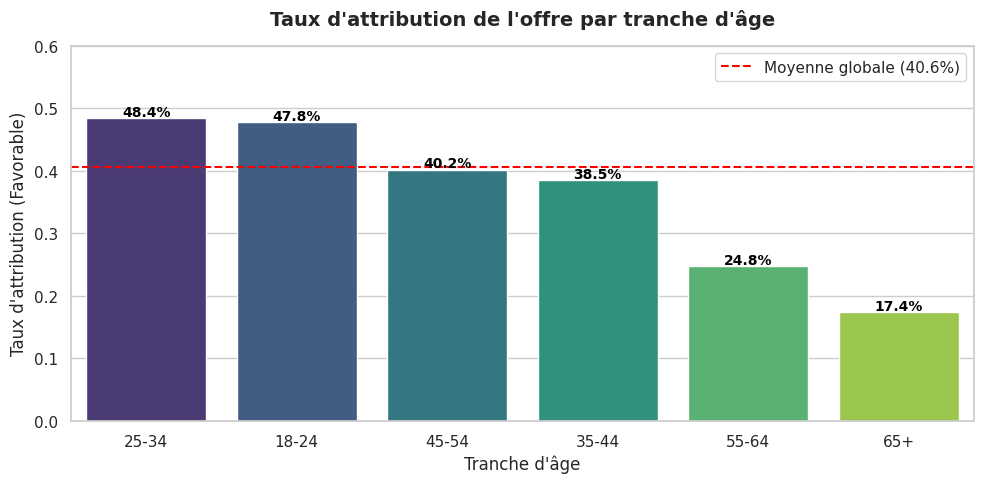

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calcul du taux d'attribution par tranche d'âge
taux_par_age = df.groupby('tranche_age')[cfg['decision']].mean().reset_index()
taux_par_age = taux_par_age.sort_values(by=cfg['decision'], ascending=False)

# Création de la figure
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(
    x='tranche_age',
    y=cfg['decision'],
    data=taux_par_age,
    palette='viridis',
    hue='tranche_age',
    legend=False,
    ax=ax
)

# Personnalisation du graphique
ax.set_title("Taux d'attribution de l'offre par tranche d'âge", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Tranche d'âge", fontsize=12)
ax.set_ylabel("Taux d'attribution (Favorable)", fontsize=12)
ax.axhline(y.mean(), color='red', linestyle='--', label=f"Moyenne globale ({y.mean():.1%})")
ax.set_ylim(0, 0.6)

# Ajout des pourcentages au-dessus des barres
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1%}",
                (p.get_x() + p.get_width() / 2., p.get_height() + 0.01),
                ha='center', va='center', fontsize=10, color='black', fontweight='semibold')

plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

Le graphique confirme de manière très visuelle une nette rupture générationnelle dans l'attribution de l'offre.
Les moins de 34 ans ont près de 50% de chances de recevoir l'offre personnalisée, alors que cette probabilité chute de façon continue pour atteindre seulement 17% chez les seniors de 65 ans et plus.La moyenne globale (représentée par la ligne pointillée rouge) se situe à 40.6%, mais elle masque des inégalités profondes : seules les trois tranches d'âge les plus jeunes se situent au-dessus de cette moyenne.

## 3. Les croisements
Un biais peut se cacher dans un croisement. Calculez le taux par combinaison de deux variables sensibles.

taux_favorable  effectif
tranche_age region                                 
18-24       Nord-Est             0.458167     502.0
            Ouest                0.500000     646.0
            Outre-mer            0.392857      28.0
            Sud-Est              0.493169     732.0
            Sud-Ouest            0.490385     416.0
            inconnu              0.483871      31.0
            Île-de-France        0.460134    1041.0
25-34       Nord-Est             0.490024    1253.0
            Ouest                0.474889    1354.0
            Outre-mer            0.247788     113.0
            Sud-Est              0.475040    1242.0
            Sud-Ouest            0.465476     840.0
            inconnu              0.430556      72.0
            Île-de-France        0.510894    2249.0
35-44       Nord-Est             0.376258     994.0
            Ouest                0.359423     971.0
            Outre-mer            0.268293      82.0
            Sud-Est              0.400898    1337.0
            Sud-Ouest            0.400602     664.0
            inconnu              0.313433      67.0
            Île-de-France        0.393692    1839.0
45-54       Nord-Est             0.400000     710.0
            Ouest                0.412533     766.0
            Outre-mer            0.337500      80.0
            Sud-Est              0.373266     793.0
            Sud-Ouest            0.427586     435.0
            inconnu              0.297297      37.0
            Île-de-France        0.411947    1289.0
55-64       Nord-Est             0.260317     315.0
            Ouest                0.205357     336.0
            Outre-mer            0.038462      26.0
            Sud-Est              0.275000     440.0
            Sud-Ouest            0.261062     226.0
            inconnu              0.130435      23.0
            Île-de-France        0.252226     674.0
65+         Nord-Est             0.144068     236.0
            Ouest                0.182648     219.0
            Outre-mer            0.041667      24.0
            Sud-Est              0.183333     300.0
            Sud-Ouest            0.200000     200.0
            inconnu              0.250000       8.0
            Île-de-France        0.173278     479.0

tranche_age,18-24,25-34,35-44,45-54,55-64,65+
region,,,,,,
Nord-Est,0.458,0.490,0.376,0.400,0.260,0.144
Ouest,0.500,0.475,0.359,0.413,0.205,0.183
Outre-mer,0.393,0.248,0.268,0.338,0.038,0.042
Sud-Est,0.493,0.475,0.401,0.373,0.275,0.183
Sud-Ouest,0.490,0.465,0.401,0.428,0.261,0.200
inconnu,0.484,0.431,0.313,0.297,0.130,0.250
Île-de-France,0.460,0.511,0.394,0.412,0.252,0.173


Ratio min/max sur le croisement tranche_age × region : 0.08


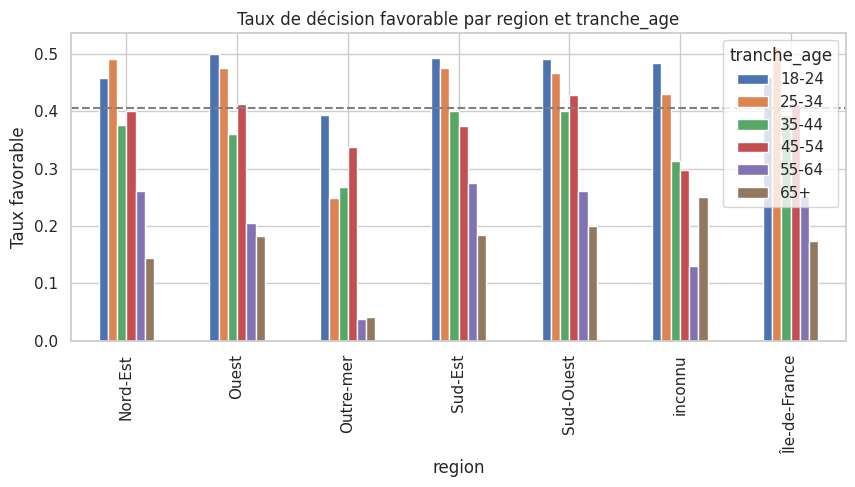

In [ ]:
# ✍️ À VOUS : remplacez les ... et traitez les TODO
# Croisement des deux variables sensibles aux ratios de parité les plus faibles
v1, v2 = synthese["variable"].iloc[:2]
mf2 = MetricFrame(metrics={"taux_favorable": selection_rate, "effectif": count},
                  y_true=y, y_pred=y, sensitive_features=df[[v1, v2]])
display(mf2.by_group)

croise = mf2.by_group["taux_favorable"].unstack(v1)
display(croise.round(3))
print(f"Ratio min/max sur le croisement {v1} × {v2} : {mf2.ratio()['taux_favorable']:.2f}")

croise.plot(kind="bar", figsize=(10, 4), title=f"Taux de décision favorable par {v2} et {v1}")
plt.ylabel("Taux favorable"); plt.axhline(y.mean(), color="gray", linestyle="--"); plt.show()


On observe que le taux d'attribution de l'offre personnalisée varie énormément selon les groupes croisés, avec un ratio min/max de seulement 0.08 entre les extrêmes.Ce sont les populations les plus jeunes (18-24 et 25-34 ans) qui bénéficient massivement de l'offre (souvent proche de 50%), et ce, dans presque toutes les régions.
À l'inverse, les seniors de 65 ans et plus (notamment dans le Nord-Est et en Outre-mer) ont des taux d'attribution extrêmement faibles (parfois sous la barre des 15%).
L'Outre-mer subit un double effet négatif : déjà globalement sous-représentée, cette région affiche des taux d'attribution quasi nuls pour les plus de 55 ans.


## 4. Les corrélations induites
La disparité la plus forte persiste-t-elle **à segment égal** ? Comparez les taux par variable sensible à l'intérieur de chaque segment métier.

In [ ]:
# ✍️ À VOUS : remplacez les ... et traitez les TODO
var = synthese["variable"].iloc[0]          # variable la plus disparate
segment_col = cfg["segment"]

mf_induit = MetricFrame(metrics={"taux_favorable": selection_rate, "effectif": count},
                        y_true=y, y_pred=y, sensitive_features=df[var],
                        control_features=df[segment_col])   # calcul à l'intérieur de chaque segment
display(mf_induit.by_group["taux_favorable"].unstack(var).round(3))

# Si le ratio reste bas dans chaque segment, le segment n'explique pas la disparité
comparaison = pd.DataFrame({"ratio_dans_le_segment": mf_induit.ratio()["taux_favorable"]})
comparaison.loc["global"] = synthese.set_index("variable").loc[var, "ratio"]
display(comparaison.round(2))

# Composition des segments : la variable sensible est-elle liée au segment (proxy) ?
display(pd.crosstab(df[segment_col], df[var], normalize="index").round(3))


tranche_age,18-24,25-34,35-44,45-54,55-64,65+
canal,,,,,,
app,0.518,0.521,0.425,0.444,0.348,0.242
magasin,0.460,0.448,0.350,0.354,0.224,0.138
web,0.487,0.513,0.411,0.443,0.284,0.264


,ratio_dans_le_segment
canal,
app,0.46
magasin,0.30
web,0.51
global,0.36


tranche_age,18-24,25-34,35-44,45-54,55-64,65+
canal,,,,,,
app,0.150,0.313,0.272,0.177,0.052,0.035
magasin,0.135,0.278,0.226,0.159,0.116,0.086
web,0.146,0.314,0.267,0.184,0.054,0.036


À segment égal (canal d'achat) : On remarque que la disparité sur la tranche d'âge persiste fortement. Le ratio reste bas au sein de chaque canal (0.46 pour l'App, 0.30 pour le Magasin, et 0.51 sur le Web).Bien que le canal Web/App favorise naturellement une population plus jeune, le segment d'achat n'explique pas à lui seul la disparité : même en magasin, les jeunes sont largement privilégiés par rapport aux seniors.Le canal de vente agit donc comme un léger facteur de corrélation, mais il y a un biais propre à la tranche d'âge qui n'est pas uniquement lié au choix du canal.


**Lecture** : la disparité vient-elle de la variable sensible elle-même, ou d'un proxy ?

## 5. L'évolution dans le temps
La disparité a-t-elle changé avec l'événement du brief ? Comparez les taux avant et après la date.

In [ ]:
# ✍️ À VOUS : remplacez les ... et traitez les TODO
date_evt = pd.to_datetime(cfg["evenement"][0])
df["date_commande"] = pd.to_datetime(df[cfg["date"]])
df["periode"] = np.where(df["date_commande"] < date_evt, "1. Avant", "2. Après")

mf_temps = MetricFrame(metrics={"taux_favorable": selection_rate, "effectif": count},
                       y_true=y, y_pred=y, sensitive_features=df[var],
                       control_features=df["periode"])
display(mf_temps.by_group["taux_favorable"].unstack("periode").round(3))

evol = pd.DataFrame({"ecart": mf_temps.difference()["taux_favorable"],
                     "ratio": mf_temps.ratio()["taux_favorable"]})
display(evol.round(3))


periode,1. Avant,2. Après
tranche_age,,
18-24,0.482,0.476
25-34,0.475,0.489
35-44,0.382,0.387
45-54,0.396,0.405
55-64,0.230,0.257
65+,0.164,0.179


,ecart,ratio
periode,,
1. Avant,0.318,0.341
2. Après,0.309,0.367


La comparaison avant/après l'événement (refonte du site et lancement de l'application le 15 avril 2024) montre que la disparité est restée quasiment identique.Le ratio de parité démographique stagne aux alentours de 0.34 - 0.36 et l'écart reste d'environ 31 points de pourcentage.Le lancement de la nouvelle application et la refonte du site n'ont pas corrigé le biais de sélection envers les tranches d'âge plus âgées.

## 6. L'égalité des chances
Quand le résultat réel est connu, comparez le **taux de vrais positifs** par groupe : parmi ceux pour qui le résultat a été favorable, quelle part avait reçu la décision favorable ?

In [ ]:
# ✍️ À VOUS : remplacez les ... et traitez les TODO
df_connu = df[df[cfg["resultat"]].notna()]
y_true_connu = df_connu[cfg["resultat"]].astype(int)
y_pred_connu = df_connu[cfg["decision"]].astype(int)
print(f"Résultat connu pour {len(df_connu)} lignes sur {len(df)}")

mf_chances = MetricFrame(
    metrics={"taux_vrais_positifs": true_positive_rate,
             "taux_favorable": selection_rate,
             "nb_resultats_favorables": lambda yt, yp: int(yt.sum()),  # base du TPR
             "effectif": count},
    y_true=y_true_connu, y_pred=y_pred_connu,
    sensitive_features=df_connu[var])
display(mf_chances.by_group)

print(f"Écart d'égalité des chances (TPR max - min) : {mf_chances.difference()['taux_vrais_positifs']:.3f}")
print(f"Ratio TPR min/max : {mf_chances.ratio()['taux_vrais_positifs']:.2f}")


Résultat connu pour 24089 lignes sur 24089


,taux_vrais_positifs,taux_favorable,nb_resultats_favorables,effectif
tranche_age,,,,
18-24,0.541241,0.477915,1273.0,3396.0
25-34,0.553631,0.483785,2713.0,7123.0
35-44,0.464416,0.384951,2192.0,5954.0
45-54,0.463984,0.401703,1541.0,4110.0
55-64,0.302511,0.247549,876.0,2040.0
65+,0.208469,0.173943,614.0,1466.0


Écart d'égalité des chances (TPR max - min) : 0.345
Ratio TPR min/max : 0.38


L'analyse du taux de vrais positifs (TPR) montre un écart flagrant d'égalité des chances (0.345 d'écart et un ratio de 0.38).Parmi les clients qui allaient effectivement racheter dans les 90 jours (ceux pour qui l'offre était légitime et utile), les jeunes ont eu une probabilité beaucoup plus élevée de recevoir l'offre personnalisée que les seniors.Ce résultat confirme que l'algorithme ne se contente pas de cibler les profils actifs, mais discrimine indirectement les seniors à potentiel de rachat équivalent.

## 7. Les limites de votre analyse
Listez au moins trois limites : données, référence, méthode.

Voici trois limites majeures concernant notre étude des biais :
Limite sur les données (Représentativité et Données manquantes) :
Nous avons observé de fortes sur-représentations sur certaines tranches d'âge (les moins de 34 ans sont deux fois plus nombreux que dans la population de référence). De plus, certaines informations sensibles comme la région comportent des valeurs "inconnu". Si les données collectées ne reflètent pas la réalité démographique de base, l'algorithme entraîné dessus risque d'automatiser et de perpétuer ces asymétries.
Limite sur la population de référence :
La population de référence statistique nationale (reference_population.csv) sert de point de comparaison global, mais elle n'est pas forcément représentative de notre cible commerciale théorique (notre marché cible spécifique ou notre secteur d'activité). Comparer nos clients actifs à la population nationale générale peut fausser notre diagnostic de sur/sous-représentation.
Limite sur la méthode et les métriques de biais :
L'analyse repose sur des métriques de parité simples (parité démographique, égalité des chances). Or, ces métriques peuvent être contradictoires (on ne peut pas toujours optimiser en même temps la parité démographique et l'égalité des chances si les taux de base diffèrent entre groupes). De plus, l'analyse ne prend pas en compte les variables latentes ou les interactions multi-critères plus complexes qui pourraient expliquer certains choix de l'algorithme de façon juste.

## 💾 Livrable de fin de journée
Votre notebook d'analyse complet, chaque choix justifié dans une cellule markdown, enregistré dans GitHub :
*Fichier › Enregistrer une copie dans GitHub*, message « Jour 1 : analyse et biais ». Envoyez le lien du dépôt au formateur.